#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [28]:
import requests
from io import BytesIO

base = "https://raw.githubusercontent.com/masakulaYOU/UCMerced_LandUse/master/Images"
terrains = {'forest': 'forest/forest00.tif',
            'urban': 'denseresidential/denseresidential00.tif',
            'ocean/beach': 'beach/beach02.tif',
            'farmland': 'agricultural/agricultural02.tif'}

Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [29]:
img = Image.open(BytesIO(requests.get(f"{base}/{terrains['ocean/beach']}").content))
imggray = img.convert('L')

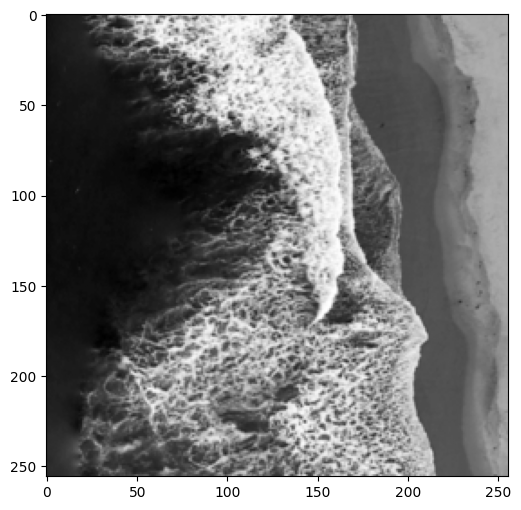

In [30]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

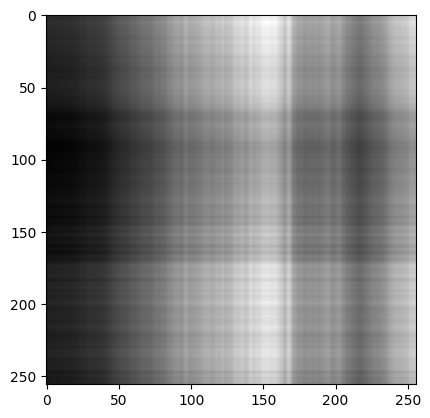

In [31]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

### 0. Answer

For a decent reconstruction we can use `k = 50` (PSNR = 32.9dB; SSIM = 0.90), with `k = 75` we get nearly indistinguishable reconstruction (PSNR = 37.3dB; SSIM = 0.95). When it comes to omitting first 1-2 vectors is not recommended, as first component carries overall brightness and removing it basically destroys the image as it'll be almost black as illustrated below.

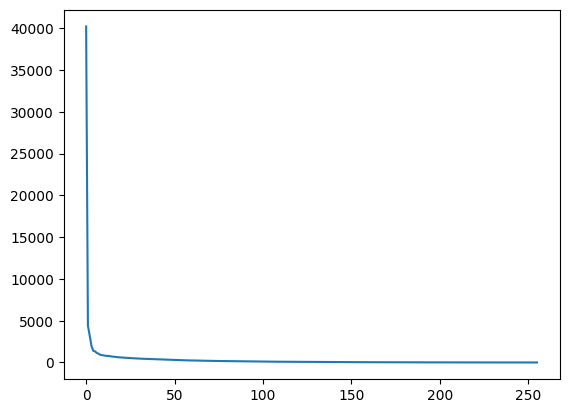

In [32]:
U.shape
sigma.shape
plt.plot(sigma)

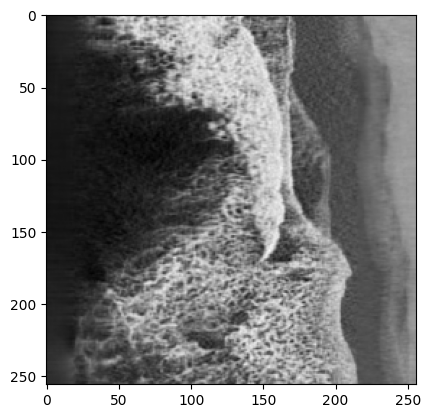

In [33]:
i = 50
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

### 1. how many values are enough?

As presented in the optimal Eigen values for this image are around `k = 75` if we aim for PSNR of over 35dB and SSIM of over 0.95, although around `k = 20` the image is distingishable.

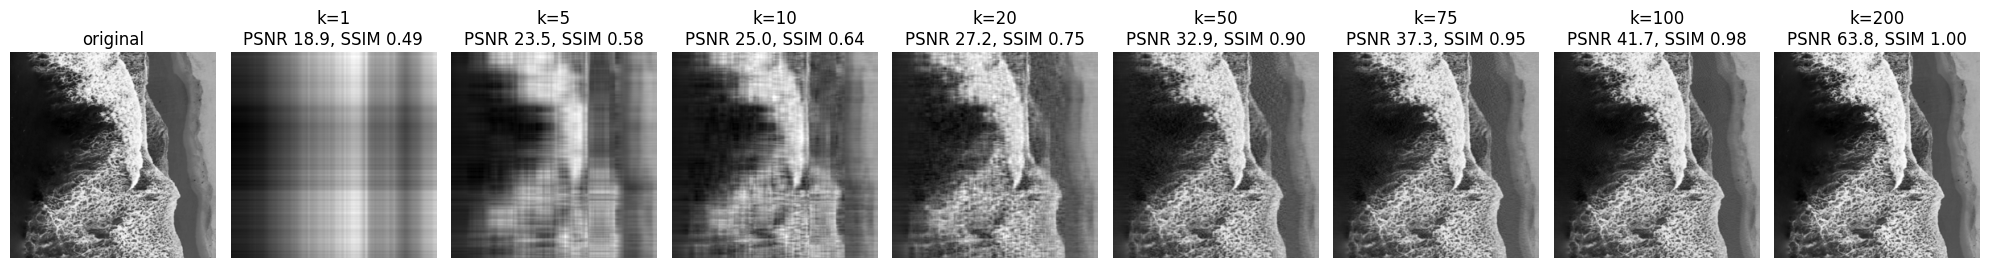

In [34]:
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

A = np.asarray(imgmat)
ks = [1, 5, 10, 20, 50, 75, 100, 200]

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(20, 3.5))
axes[0].imshow(A, cmap='gray')
axes[0].set_title('original')

for ax, k in zip(axes[1:], ks):
    recon = np.asarray(U[:, :k] @ np.diag(sigma[:k]) @ V[:k, :])
    recon = np.clip(recon, 0, 255)
    p = psnr(A, recon, data_range=255)
    s = ssim(A, recon, data_range=255)
    ax.imshow(recon, cmap='gray')
    ax.set_title(f'k={k}\nPSNR {p:.1f}, SSIM {s:.2f}')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

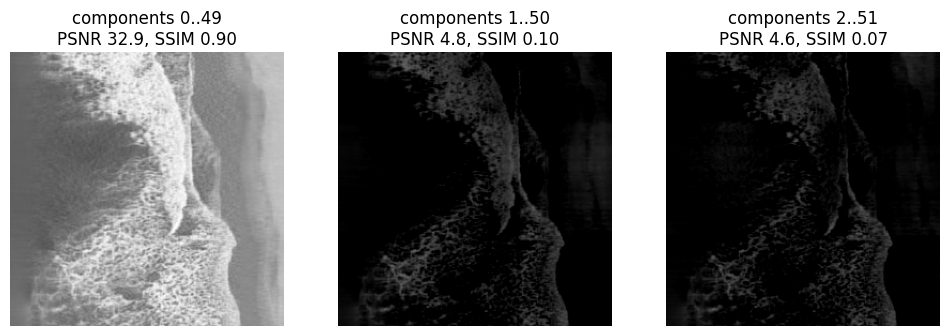

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, j in zip(axes, [0, 1, 2]):
    R = np.asarray(U[:, j:j+50] @ np.diag(sigma[j:j+50]) @ V[j:j+50, :])
    Rc = np.clip(R, 0, 255)
    p = psnr(np.asarray(imgmat), Rc, data_range=255)
    s = ssim(np.asarray(imgmat), Rc, data_range=255)
    ax.imshow(Rc, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'components {j}..{j+49}\nPSNR {p:.1f}, SSIM {s:.2f}')
    ax.axis('off')
plt.show()

### 2. components 10..k+10 instead of the top k

Skipping 10 first components removes overall brightness and large shapes, that are carried by the largest singular values. What remains is mostly textures and edges causing the whole image to look like gray edge map where there's no improvement with increase of k value.

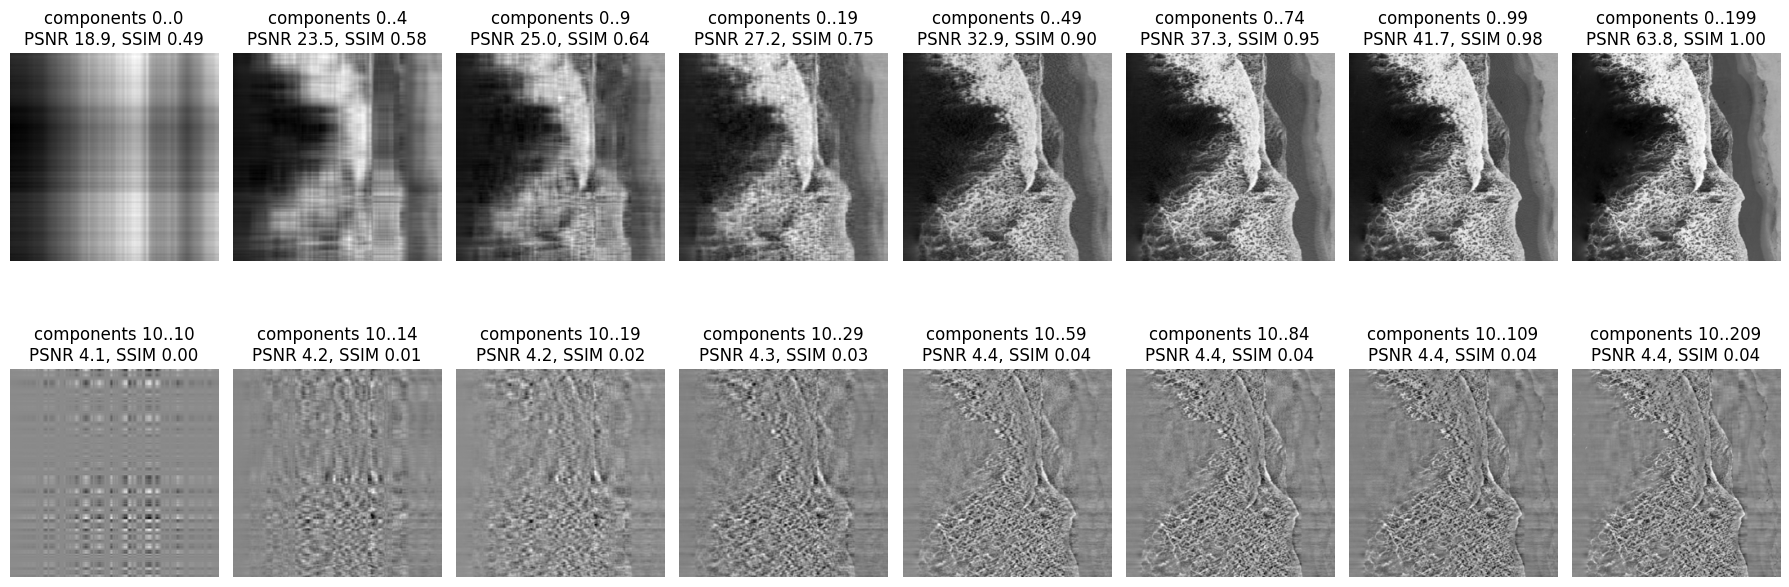

In [36]:
A = np.asarray(imgmat)
U, sigma, V = np.linalg.svd(A)

def recon(U, sigma, V, j, i):
    return U[:, j:i] @ np.diag(sigma[j:i]) @ V[j:i, :]

fig, axes = plt.subplots(2, len(ks), figsize=(18, 7))
for col, k in enumerate(ks):
    row_out = []
    for row, j in enumerate([0, 10]):
        R = recon(U, sigma, V, j, j + k)
        Rc = np.clip(R, 0, 255)
        p, s = psnr(A, Rc, data_range=255), ssim(A, Rc, data_range=255)
        row_out += [p, s]
        axes[row, col].imshow(R, cmap='gray')
        axes[row, col].set_title(f'components {j}..{j+k-1}\nPSNR {p:.1f}, SSIM {s:.2f}')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

### 3. Different terrains

All checked terrain types hit the optimal values around the same range of `k = [50, 75]` for reconstruction without visible degradation. This shows that what's important is the amount of fine texture and edges rather than a terrain type itself.

In [37]:
def load_gray(path):
    img = Image.open(BytesIO(requests.get(f"{base}/{path}").content))
    return np.asarray(img.convert('L'), dtype=float)

results = {}
for label, path in terrains.items():
    A = load_gray(path)
    U_t, sigma_t, V_t = np.linalg.svd(A)
    results[label] = dict(A=A, U=U_t, sigma=sigma_t, V=V_t)

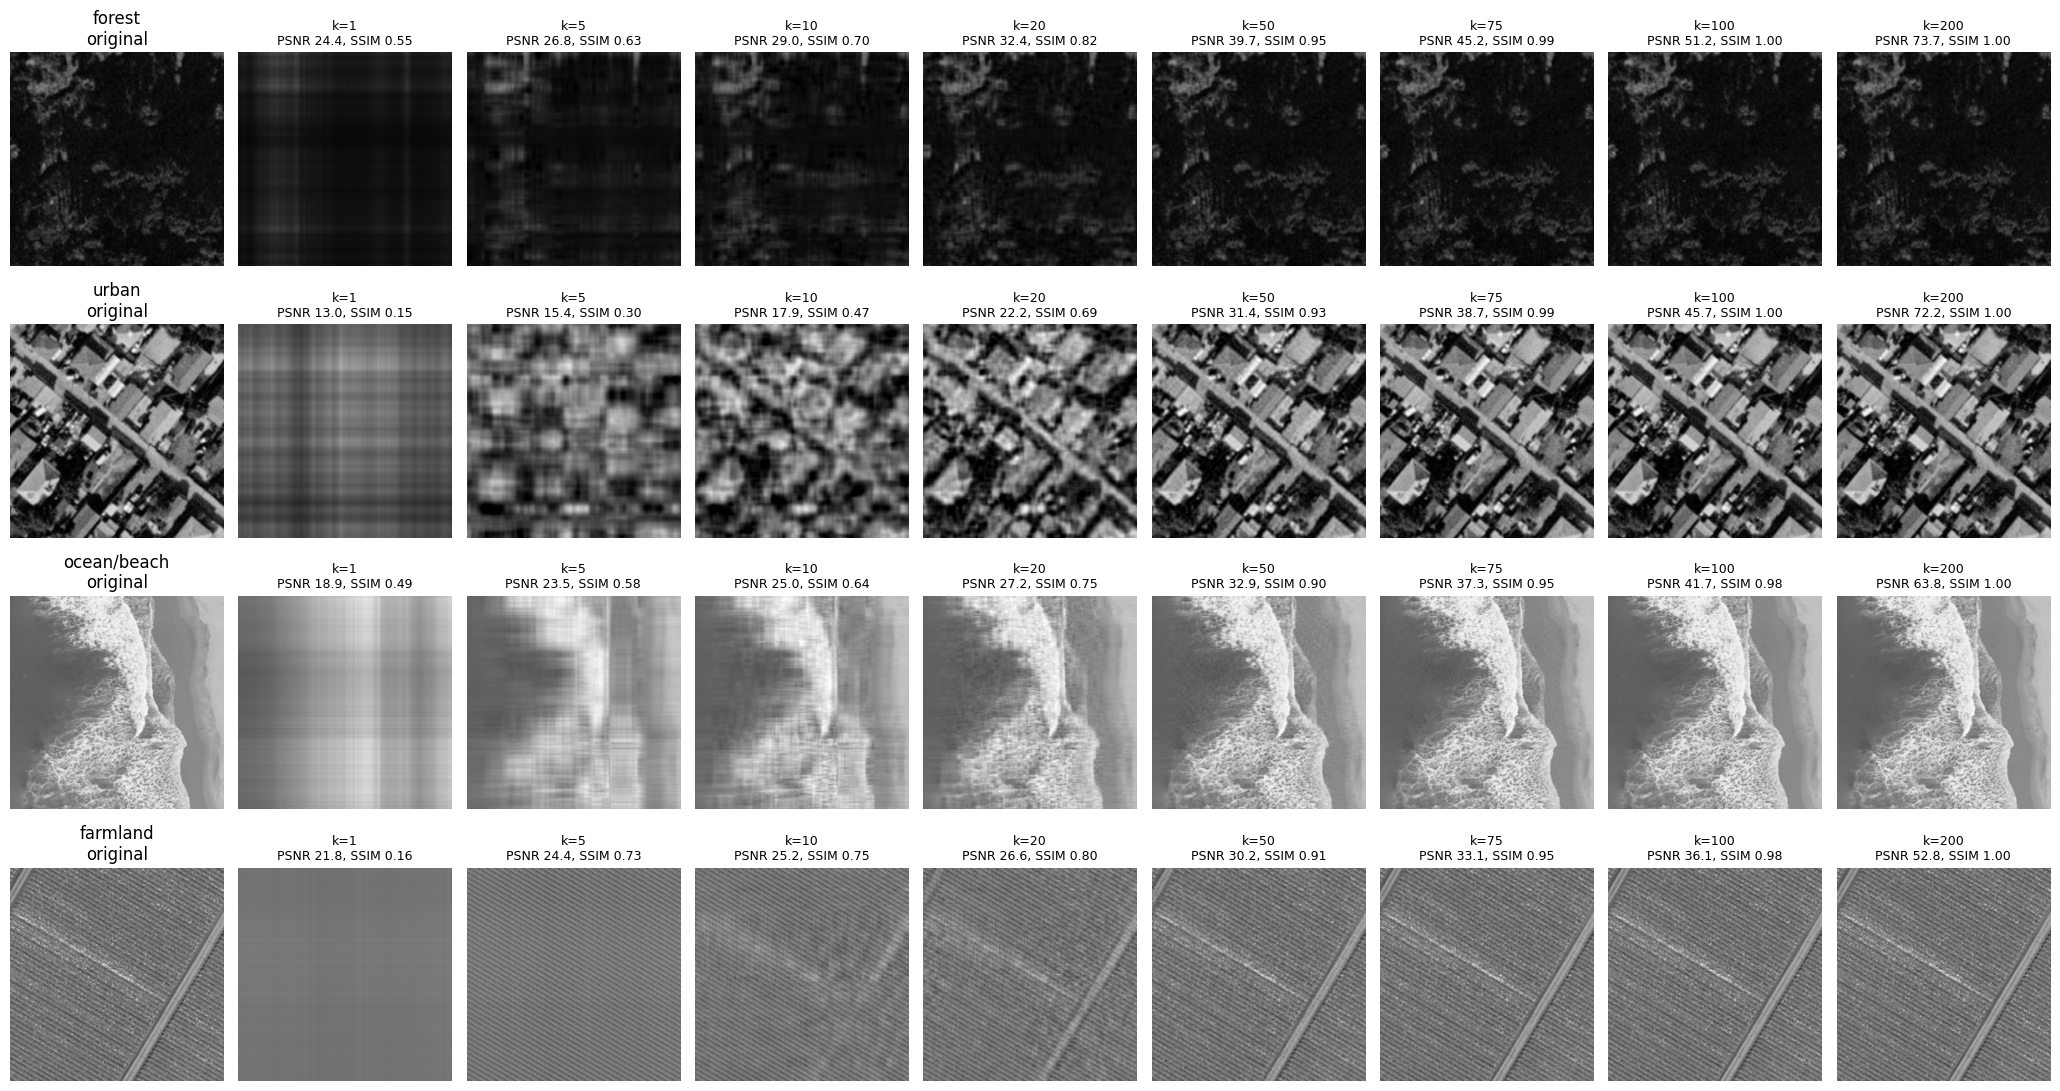

In [38]:
fig, axes = plt.subplots(len(results), len(ks) + 1, figsize=(2.3 * (len(ks) + 1), 2.8 * len(results)))

for row, (label, r) in enumerate(results.items()):
    A = r['A']
    axes[row, 0].imshow(A, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'{label}\noriginal')
    for col, k in enumerate(ks, start=1):
        R = np.clip(r['U'][:, :k] @ np.diag(r['sigma'][:k]) @ r['V'][:k, :], 0, 255)
        p = psnr(A, R, data_range=255)
        s = ssim(A, R, data_range=255)
        axes[row, col].imshow(R, cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'k={k}\nPSNR {p:.1f}, SSIM {s:.2f}', fontsize=9)

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()